# Machine Learning for Sound and Music 2026
## Lab 2: Music Genre Classification using CNNs
##### Author: Lidia Wiśniewska
-----
### Background
Convolutional Neural Networks (CNNs) have become increasingly popular for audio
classification tasks, driven by their remarkable success in computer vision. Originally
designed to exploit the spatial hierarchies of visual data, CNN architectures have been
effectively adapted to analyse time–frequency representations of audio signals, such as
spectrograms or Mel-spectrograms. This adaptation leverages the CNNs’ ability to learn
local and hierarchical features, enabling them to capture important temporal and
spectral patterns in sound. Many techniques and architectures that proved successful in
vision, such as VGG, ResNet, and Inception, have been transferred to audio analysis,
where they demonstrate strong performance in tasks like speech recognition, music
genre classification, and environmental sound identification. This cross-domain success
illustrates how insights from visual deep learning research have profoundly shaped and
accelerated progress in computational audio understanding.

---
### Approach
This notebook implements genre classification on the mel-spectrogram images:
- **Task 1:** a baseline CNN trained from scratch, two modest architecture comparisons, and Optuna tuning of Adam learning rate, batch size, weight decay, and dropout.
- **Task 2:** fine-tuning of an ImageNet-pretrained ResNet-18 (frozen backbone vs. full fine-tuning, plus the same training hyper-parameters).
- **Comparison with Lab 1:** the split (train / val / test file names) is saved to csv files and applied in the Lab 1 notebook; the Lab 1 test predictions are loaded back here.

CNN classes are in `model_helpers.py`, helper functions in `util_functions.py`.

---
### Structure
The notebook structure looks as follows: <br>
    1. [Data loading](#1-data-loading)<br>
    2. [Train / validation / test split](#2-split)<br>
    3. [Task 1 – CNN from scratch](#3-task1)<br>
    4. [Task 2 – Fine-tuning a pretrained model](#4-task2)<br>
    5. [Lab 1 results on the same split](#5-lab1)<br>
    6. [Evaluation of all models](#6-evaluation)<br>
    7. [Research questions](#7-rq)<br>

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

import importlib
import model_helpers as MF
import util_functions as UF
importlib.reload(MF)
importlib.reload(UF)

SEED = 42
UF.set_seed(SEED)
device = UF.get_device()
print("device:", device)

DATA_DIR = Path("./data")
IMG_DIR = DATA_DIR / "images_original"
SPLIT_DIR = Path("./splits")               # split files for Lab 1
LAB1_DIR = Path("./lab1_predictions")      # Lab 1 test predictions (written by the Lab 1 notebook)
MODEL_DIR = Path("./models")
for d in (SPLIT_DIR, LAB1_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

device: mps


<a id="1-data-loading"></a>
## 1. Data loading
The spectrogram PNGs are matplotlib figures with a white margin around the spectrogram - as it gives no information, I am cropping the margin (the crop box is found from the average image). Two versions are kept: grey-scale (1 channel) for our CNNs and RGB for the ImageNet-pretrained ResNet.

**Duplicates.** In Lab 1 we found 14 pairs of identical tracks in GTZAN (one of them with two different labels). Identical audio gives identical spectrograms, so if one copy is in the training set and the other in the test set, the model is tested on a song it has already seen. We remove the same 15 songs as in Lab 1, so that both labs use exactly the same songs. `jazz.00054` has no spectrogram (the audio file is corrupted).

=== DATASET SANITY CHECK ===
Total samples : 984
Classes       : ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Crop box      : (35, 253, 54, 390) (top, bottom, left, right)
Gray images   : (984, 1, 218, 336)
RGB images    : (984, 3, 218, 336)


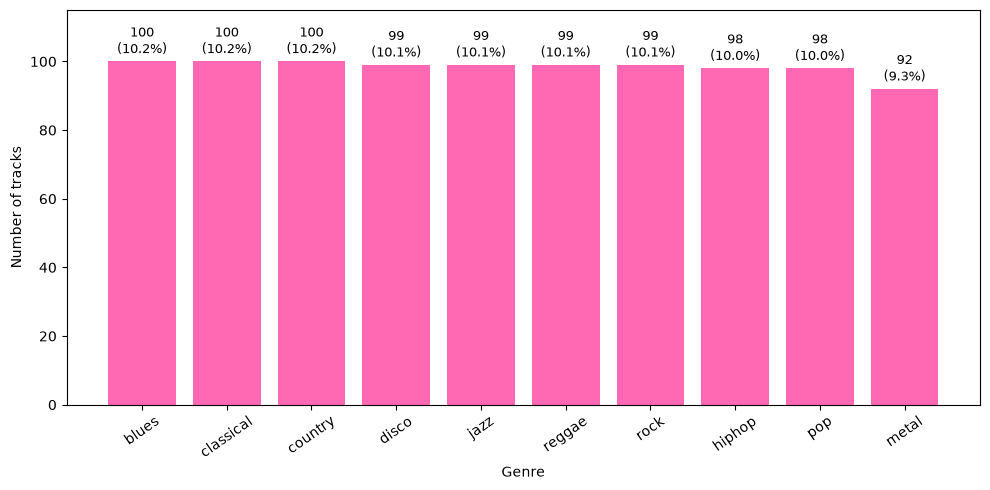

In [4]:
# songs removed in Lab 1 (identical copies; metal.00058 / rock.00016 is the same track with two labels)
LAB1_DROPPED = ['disco.00099', 'hiphop.00045', 'hiphop.00078', 'metal.00058', 'metal.00061', 'metal.00062',
                'metal.00063', 'metal.00064', 'metal.00065', 'metal.00066', 'metal.00094', 'pop.00060',
                'pop.00071', 'reggae.00082', 'rock.00016']

data = UF.load_images(IMG_DIR, drop_files=[s + ".wav" for s in LAB1_DROPPED])
classes = data["classes"]
labels = data["labels"]

print("=== DATASET SANITY CHECK ===")
print(f"Total samples : {len(labels)}")
print(f"Classes       : {classes}")
print(f"Crop box      : {data['crop_box']} (top, bottom, left, right)")
print(f"Gray images   : {tuple(data['gray'].shape)}")
print(f"RGB images    : {tuple(data['rgb'].shape)}")
# display(pd.Series(np.array(classes)[labels]).value_counts().sort_index().to_frame("songs"))

arget_col_name = "genres"
counts = pd.Series(np.array(classes)[labels]).value_counts().sort_values(ascending=False)
total = counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color="hotpink")
ax.bar_label(
    bars,
    labels=[f"{count}\n({count / total:.1%})" for count in counts.values],
    padding=3,
    fontsize=9,
)
ax.set(
    title="",
    xlabel="Genre",
    ylabel="Number of tracks",
)
ax.tick_params(axis="x", rotation=35)
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

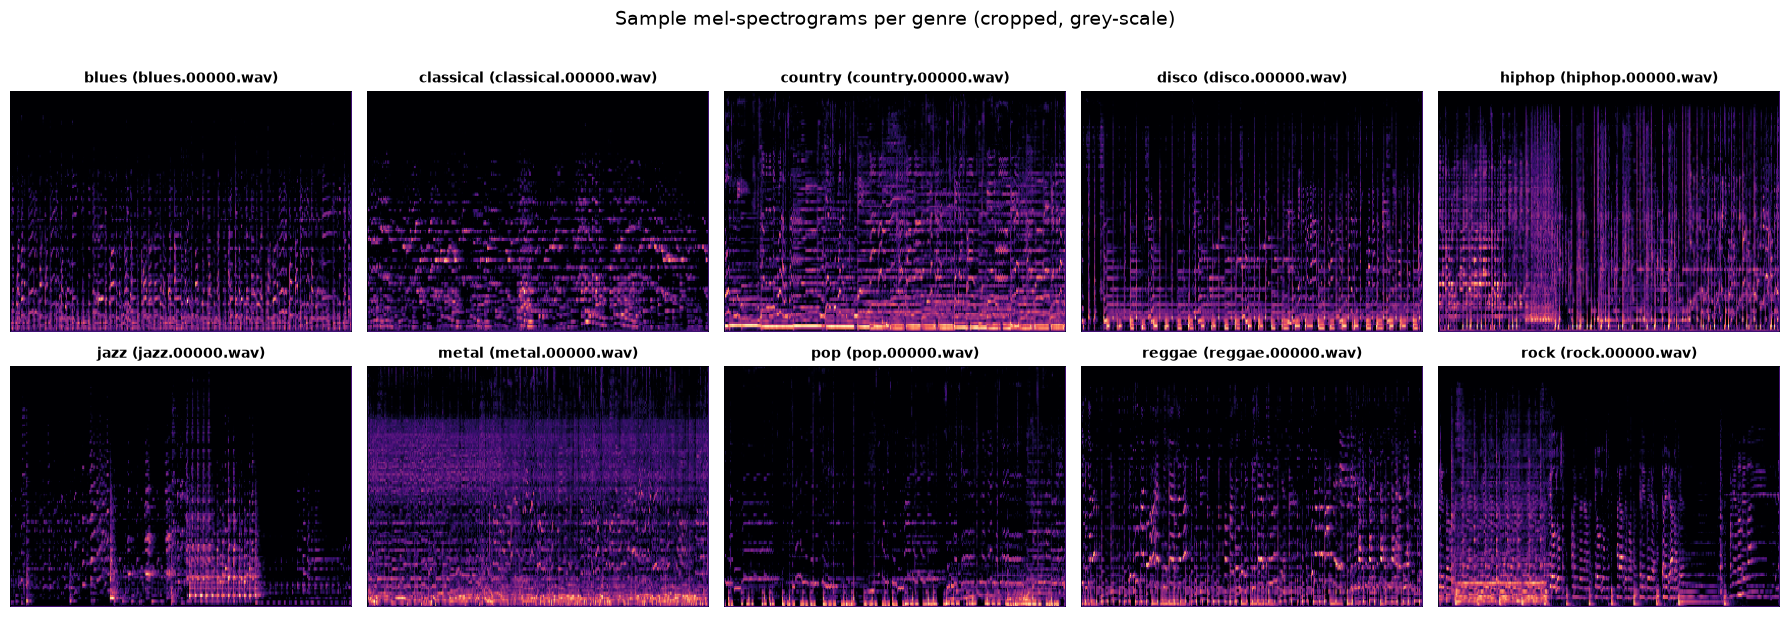

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, c in zip(axes.ravel(), range(len(classes))):
    i = np.where(labels == c)[0][0]
    ax.imshow(data["gray"][i, 0], aspect="auto", cmap="magma")
    ax.set_title(f"{classes[c]} ({data['filenames'][i]})", fontsize=10, fontweight="bold")
    ax.axis("off")
plt.suptitle("Sample mel-spectrograms per genre (cropped, grey-scale)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

<a id="2-split"></a>
## 2. Train / validation / test split
Every song is one image, so we split the images directly with a shuffled, **stratified** split (`train_test_split`):
* 80 % train+val / 20 % test (≈197 test songs),
* the 80 % is split again 80/20 into **train** and **val**.

`train` and `val` are used to choose the architecture and hyper-parameters. The final model is then retrained on `train`+`val` (the full 80 %) and evaluated once on `test`.

The split is saved as `splits/split_seed{seed}.csv`, with columns `filename` (same format as `features_30_sec.csv`), `genre` and `split` (`train` / `val` / `test`). The Lab 1 models are trained and evaluated on these files (section 5). For RQ5 the same is done for 4 more seeds, and for RQ6 the seed-42 file has extra columns `in_10pct`, `in_25pct` and `in_50pct`, which mark stratified subsets of the training songs.

In [6]:
RQ5_SEEDS = [42, 123, 8]
RQ6_FRACTIONS = [0.1, 0.25, 0.5, 1.0]

splits = {seed: UF.make_split(labels, seed=seed) for seed in RQ5_SEEDS}
split = splits[SEED]
subsets = {f: UF.train_subset(split["trainval"], labels, f, seed=SEED) for f in RQ6_FRACTIONS}

for seed, sp in splits.items():
    df = pd.DataFrame({"filename": data["filenames"], "genre": np.array(classes)[labels], "split": ""})
    df.loc[sp["train"], "split"] = "train"
    df.loc[sp["val"], "split"] = "val"
    df.loc[sp["test"], "split"] = "test"
    if seed == SEED:
        for f in RQ6_FRACTIONS[:-1]:
            df[f"in_{int(f * 100)}pct"] = False
            df.loc[subsets[f], f"in_{int(f * 100)}pct"] = True
    df.to_csv(SPLIT_DIR / f"split_seed{seed}.csv", index=False)

print("=== DATASET SPLITS (seed 42) ===")
for k in ("train", "val", "test"):
    print(f"{k:5s}: {len(split[k])} songs ({len(split[k]) / len(labels):.1%})")
print("split files:", sorted(p.name for p in SPLIT_DIR.glob("*.csv")))

# grey-scale normalisation from the training songs
x = data["gray"][split["trainval"]].float() / 255
data["gray_mean"], data["gray_std"] = x.mean().item(), x.std().item()
y_test = labels[split["test"]]
test_files = data["filenames"][split["test"]]

=== DATASET SPLITS (seed 42) ===
train: 629 songs (63.9%)
val  : 158 songs (16.1%)
test : 197 songs (20.0%)
split files: ['split_seed123.csv', 'split_seed42.csv', 'split_seed8.csv']


<a id="3-task1"></a>
## 3. Task 1 – CNN trained from scratch

### 3.1 Baseline
- 3 × [Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2] with 16, 32, 64 filters
- Adaptive average pool to 1×1 per channel → Dropout(0.2) → Dense(64) → ReLU → Dense(10)
- Adam (lr 1e-3)
- batch size 32
- 20 epochs; report and save the epoch with the lowest validation loss

epoch  1 | train loss 2.261 | val loss 2.232 acc 0.177
epoch  2 | train loss 2.087 | val loss 2.035 acc 0.342
epoch  3 | train loss 1.884 | val loss 1.757 acc 0.361
epoch  4 | train loss 1.737 | val loss 1.644 acc 0.405
epoch  5 | train loss 1.636 | val loss 1.565 acc 0.411
epoch  6 | train loss 1.552 | val loss 1.542 acc 0.392
epoch  7 | train loss 1.489 | val loss 1.581 acc 0.430
epoch  8 | train loss 1.501 | val loss 1.510 acc 0.418
epoch  9 | train loss 1.459 | val loss 1.461 acc 0.475
epoch 10 | train loss 1.404 | val loss 1.623 acc 0.424
epoch 11 | train loss 1.421 | val loss 1.403 acc 0.487
epoch 12 | train loss 1.383 | val loss 1.497 acc 0.481
epoch 13 | train loss 1.335 | val loss 1.436 acc 0.500
epoch 14 | train loss 1.313 | val loss 1.392 acc 0.582
epoch 15 | train loss 1.281 | val loss 1.483 acc 0.475
epoch 16 | train loss 1.310 | val loss 1.571 acc 0.437
epoch 17 | train loss 1.281 | val loss 1.330 acc 0.633
epoch 18 | train loss 1.273 | val loss 1.520 acc 0.468
epoch 19 |

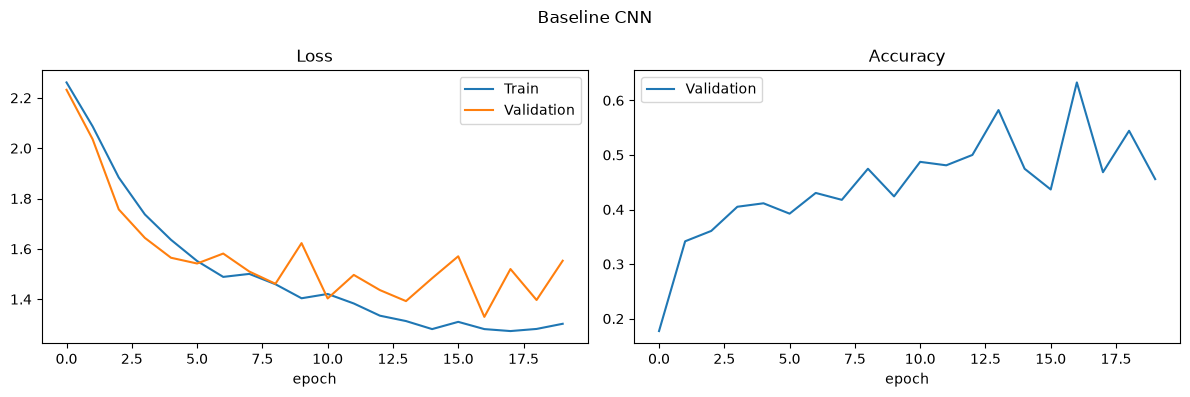

In [8]:
BASE_CONFIG = {"model": "baseline", "optimizer": "adam", "lr": 1e-3,
               "batch_size": 32, "epochs": 20}

model, history = UF.train_model(BASE_CONFIG, data, split["train"], split["val"], device, verbose=True)
print(f"parameters: {MF.count_parameters(model, trainable_only=True):,} | training time {history['train_time']:.0f}s")
best_epoch = history["best_epoch"] - 1
print(f"Best epoch {history['best_epoch']}: train loss {history['train_loss'][best_epoch]:.3f}, "
      f"val loss {history['best_val_loss']:.3f}, val accuracy {history['best_val_acc']:.3f}")
torch.save({"model_state_dict": model.state_dict(), "config": BASE_CONFIG,
            "best_epoch": history["best_epoch"], "best_val_loss": history["best_val_loss"],
            "best_val_acc": history["best_val_acc"], "classes": classes},
           MODEL_DIR / "baseline_cnn_best.pt")
UF.plot_history(history, "Baseline CNN")

### 3.2 Two small architecture changes
Compare the baseline with two controlled variants: (1) add one block but keep it at 64 filters (16–32–64–64), and (2) keep three blocks but reverse the channel order (64–32–16). The second version puts more filters in the first, higher-resolution block, so it may cost more computation; neither change is guaranteed to improve accuracy. Keep the training settings and data split fixed.

epoch  1 | train loss 2.188 | val loss 2.168 acc 0.278
epoch  2 | train loss 1.949 | val loss 2.042 acc 0.234
epoch  3 | train loss 1.750 | val loss 1.698 acc 0.386
epoch  4 | train loss 1.596 | val loss 2.056 acc 0.259
epoch  5 | train loss 1.485 | val loss 1.571 acc 0.418
epoch  6 | train loss 1.430 | val loss 2.062 acc 0.297
epoch  7 | train loss 1.408 | val loss 2.174 acc 0.291
epoch  8 | train loss 1.393 | val loss 2.716 acc 0.228
epoch  9 | train loss 1.301 | val loss 1.337 acc 0.551
epoch 10 | train loss 1.292 | val loss 1.500 acc 0.487
epoch 11 | train loss 1.186 | val loss 1.378 acc 0.494
epoch 12 | train loss 1.176 | val loss 1.754 acc 0.399
epoch 13 | train loss 1.197 | val loss 1.434 acc 0.532
epoch 14 | train loss 1.158 | val loss 2.282 acc 0.266
epoch 15 | train loss 1.091 | val loss 1.781 acc 0.405
epoch 16 | train loss 1.088 | val loss 1.667 acc 0.437
epoch 17 | train loss 1.050 | val loss 1.933 acc 0.411
epoch 18 | train loss 1.034 | val loss 1.810 acc 0.481
epoch 19 |

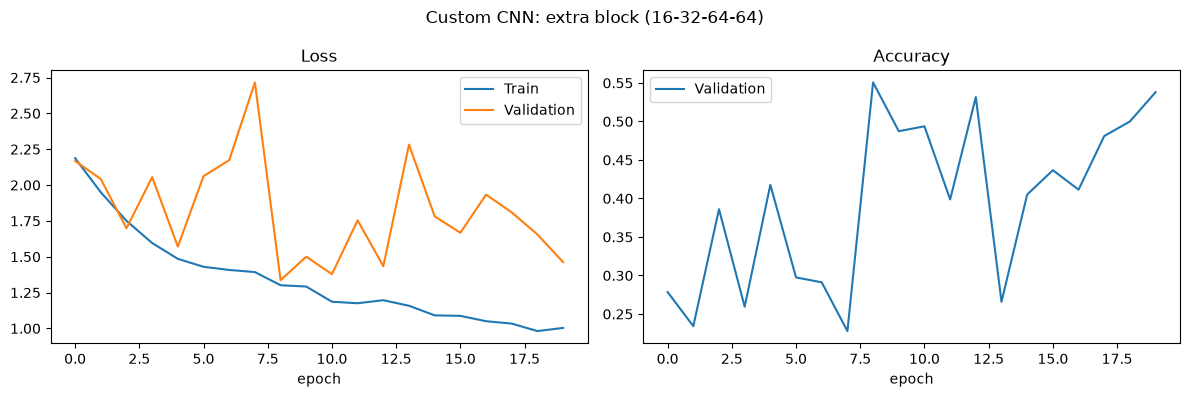

epoch  1 | train loss 2.259 | val loss 2.235 acc 0.209
epoch  2 | train loss 2.147 | val loss 2.100 acc 0.310
epoch  3 | train loss 2.040 | val loss 1.953 acc 0.278
epoch  4 | train loss 1.929 | val loss 1.869 acc 0.285
epoch  5 | train loss 1.837 | val loss 1.738 acc 0.380
epoch  6 | train loss 1.730 | val loss 1.719 acc 0.405
epoch  7 | train loss 1.708 | val loss 1.629 acc 0.424
epoch  8 | train loss 1.641 | val loss 1.679 acc 0.361
epoch  9 | train loss 1.618 | val loss 1.820 acc 0.335
epoch 10 | train loss 1.571 | val loss 1.898 acc 0.278
epoch 11 | train loss 1.574 | val loss 1.555 acc 0.437
epoch 12 | train loss 1.551 | val loss 1.563 acc 0.481
epoch 13 | train loss 1.504 | val loss 1.697 acc 0.380
epoch 14 | train loss 1.509 | val loss 2.260 acc 0.247
epoch 15 | train loss 1.529 | val loss 1.553 acc 0.424
epoch 16 | train loss 1.470 | val loss 1.647 acc 0.430
epoch 17 | train loss 1.481 | val loss 1.479 acc 0.519
epoch 18 | train loss 1.448 | val loss 1.594 acc 0.468
epoch 19 |

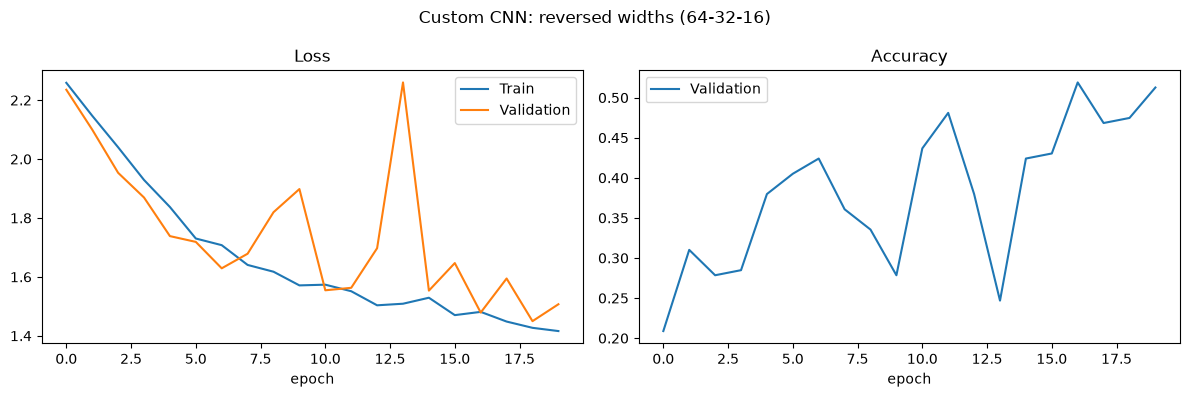

,variant,filters,parameters,best epoch,train loss,val loss,val accuracy
0,extra block (16-32-64-64),"(16, 32, 64, 64)",65210,9,1.301043,1.336530,0.550633
1,reversed widths (64-32-16),"(64, 32, 16)",25578,19,1.427083,1.449735,0.474684


Selected architecture for the small learning-rate comparison: extra block (16-32-64-64)


In [9]:
ARCHITECTURES = {
    "extra block (16-32-64-64)": {
        "model": "custom", "block_channels": (16, 32, 64, 64), "hidden_size": 64,
    },
    "reversed widths (64-32-16)": {
        "model": "custom", "block_channels": (64, 32, 16), "hidden_size": 64,
    },
}

architecture_results = []
for name, architecture in ARCHITECTURES.items():
    config = {**BASE_CONFIG, **architecture}
    model, history = UF.train_model(config, data, split["train"], split["val"], device, verbose=True)
    best_epoch = history["best_epoch"] - 1
    result = {
        "variant": name,
        "filters": architecture["block_channels"],
        "parameters": MF.count_parameters(model, trainable_only=True),
        "best epoch": history["best_epoch"],
        "train loss": history["train_loss"][best_epoch],
        "val loss": history["best_val_loss"],
        "val accuracy": history["best_val_acc"],
    }
    architecture_results.append(result)
    print(result)
    UF.plot_history(history, f"Custom CNN: {name}")

architecture_df = pd.DataFrame(architecture_results).sort_values(
    ["val loss", "val accuracy"], ascending=[True, False]
).reset_index(drop=True)
display(architecture_df)
best_variant = architecture_df.iloc[0]["variant"]
ARCH = {**ARCHITECTURES[best_variant], "dropout": BASE_CONFIG.get("dropout", 0.2)}
print("Selected architecture for the small learning-rate comparison:", best_variant)

Turns out the initial guess obtained the best results and the most stable training. Based on this, that baseline will be used for tuning hyperparameters.

### 3.3 Tuning hyper-parameters

Using the baseline architecture, tune with Optuna's TPE sampler:
- optimizer: Adam
- learning rate: float log in [1e-4, 3e-3]
- batch size: 16 / 32 / 64
- weight decay: float log in [1e-6, 1e-3]
- dropout: 0.1 to 0.5 in steps of 0.1
- up to 40 epochs per trial, with early stopping after 8 epochs without validation-loss improvement

In [13]:
import optuna

N_TRIALS = 15
MAX_EPOCHS = 40
EARLY_STOPPING_PATIENCE = 8
best_val_loss = float("inf")
hp_results = []

def objective(trial):
    global best_val_loss
    optimizer = "adam"
    lr = trial.suggest_float("lr", 1e-4, 3e-3, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True)
    dropout = trial.suggest_float("dropout", 0.1, 0.5, step=0.1)

    config = {
        **BASE_CONFIG,
        "optimizer": optimizer,
        "lr": lr,
        "weight_decay": weight_decay,
        "batch_size": batch_size,
        "dropout": dropout,
        "epochs": MAX_EPOCHS,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    }
    model, history = UF.train_model(config, data, split["train"], split["val"], device)
    best_epoch = history["best_epoch"] - 1
    result = {
        "trial": trial.number,
        "optimizer": optimizer,
        "lr": lr,
        "weight_decay": weight_decay,
        "batch_size": batch_size,
        "dropout": dropout,
        "best epoch": history["best_epoch"],
        "train loss": history["train_loss"][best_epoch],
        "val loss": history["best_val_loss"],
        "val acc": history["best_val_acc"],
        "epochs run": history["epochs_ran"],
    }
    hp_results.append(result)
    trial.set_user_attr("result", result)
    print(
        f"Trial {trial.number} (Adam, batch={batch_size}, dropout={dropout:.1f}): "
        f"best epoch {history['best_epoch']}, "
        f"train loss {result['train loss']:.3f}, val loss {result['val loss']:.3f}, "
        f"val accuracy {result['val acc']:.3f}",
        flush=True,
    )

    if history["best_val_loss"] < best_val_loss:
        best_val_loss = history["best_val_loss"]
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "config": config,
                "trial": trial.number,
                "best_epoch": history["best_epoch"],
                "best_val_loss": history["best_val_loss"],
                "best_val_acc": history["best_val_acc"],
                "classes": classes,
            },
            MODEL_DIR / f"tune_lr{lr:.2e}_bs{batch_size}_wd{weight_decay:.2e}_dropout{dropout:.1f}_best.pt",
        )
    return float(history["best_val_loss"])

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=5),
)
study.optimize(objective, n_trials=N_TRIALS)

hp_df = pd.DataFrame(hp_results).sort_values(
    ["val loss", "val acc"], ascending=[True, False]
).reset_index(drop=True)
display(hp_df.round(5))
print("Best trial:", study.best_trial.number, study.best_trial.params)
print(f"Best validation loss: {study.best_value:.4f}")

[I 2026-11-05 18:31:42,432] A new study created in memory with name: no-name-826597f8-9e26-4b2a-9807-aed88d3f8fe2


Trial 0 (Adam, batch=16, dropout=0.1): best epoch 25, train loss 1.282, val loss 1.306, val accuracy 0.557


[I 2026-11-05 18:33:24,224] Trial 0 finished with value: 1.3059917205496678 and parameters: {'lr': 0.00035747129226002455, 'batch_size': 16, 'weight_decay': 2.9380279387035354e-06, 'dropout': 0.1}. Best is trial 0 with value: 1.3059917205496678.


Trial 1 (Adam, batch=16, dropout=0.5): best epoch 38, train loss 1.591, val loss 1.518, val accuracy 0.462


[I 2026-11-05 18:35:14,390] Trial 1 finished with value: 1.5176194197014918 and parameters: {'lr': 0.00012184186502221769, 'batch_size': 16, 'weight_decay': 1.1527987128232402e-06, 'dropout': 0.5}. Best is trial 0 with value: 1.3059917205496678.


Trial 2 (Adam, batch=16, dropout=0.3): best epoch 27, train loss 1.190, val loss 1.200, val accuracy 0.627


... (23 outputs left out)

Trial 14 (Adam, batch=64, dropout=0.2): best epoch 23, train loss 1.214, val loss 1.321, val accuracy 0.589


[I 2026-11-05 18:54:52,719] Trial 14 finished with value: 1.321250574498237 and parameters: {'lr': 0.001047699118494376, 'batch_size': 64, 'weight_decay': 0.00020690550086963292, 'dropout': 0.2}. Best is trial 2 with value: 1.1996492313433298.


,trial,optimizer,lr,weight_decay,batch_size,dropout,best epoch,train loss,val loss,val acc,epochs run
0,2,adam,0.00170,0.00001,16,0.3,27,1.19048,1.19965,0.62658,35
1,5,adam,0.00151,0.00037,16,0.4,24,1.27171,1.23807,0.60759,32
2,11,adam,0.00105,0.00025,16,0.4,27,1.28232,1.24005,0.53797,35
3,4,adam,0.00047,0.00006,16,0.1,26,1.23722,1.26361,0.63924,34
4,3,adam,0.00043,0.00001,32,0.2,38,1.21451,1.27298,0.58861,40
5,10,adam,0.00157,0.00000,32,0.2,17,1.25911,1.27882,0.59494,25
6,13,adam,0.00176,0.00092,32,0.2,17,1.25565,1.28969,0.51899,25
7,0,adam,0.00036,0.00000,16,0.1,25,1.28246,1.30599,0.55696,33
8,14,adam,0.00105,0.00021,64,0.2,23,1.21382,1.32125,0.58861,31
9,6,adam,0.00200,0.00000,64,0.4,17,1.30948,1.34178,0.53165,25


Best trial: 2 {'lr': 0.0016967533607196547, 'batch_size': 16, 'weight_decay': 8.179499475211674e-06, 'dropout': 0.30000000000000004}
Best validation loss: 1.1996


The same tuning was performed for SGD, but the best results were obtained with Adam.

### 3.4 Final CNN
The best configuration is retrained on train+val (80 %) and evaluated on the test set.

In [14]:
best = hp_df.iloc[0]
CNN_CONFIG = {**BASE_CONFIG,
              "optimizer": str(best["optimizer"]),
              "lr": float(best["lr"]),
              "weight_decay": float(best["weight_decay"]),
              "dropout": float(best["dropout"]),
              "batch_size": int(best["batch_size"]),
              "epochs": int(best["best epoch"])}
print("final CNN configuration:", CNN_CONFIG)

cnn_model, cnn_history = UF.train_model(CNN_CONFIG, data, split["trainval"], None, device)
torch.save(cnn_model.state_dict(), MODEL_DIR / "cnn_scratch.pt")
cnn_proba, cnn_pred = UF.predict(cnn_model, data, CNN_CONFIG, split["test"], device)
acc, lo, hi = UF.accuracy_ci(y_test, cnn_pred)
print(f"CNN test accuracy: {acc:.3f} (95% CI {lo:.3f}-{hi:.3f}) | training time {cnn_history['train_time']:.0f}s")

final CNN configuration: {'model': 'baseline', 'optimizer': 'adam', 'lr': 0.0016967533607196547, 'batch_size': 16, 'epochs': 27, 'weight_decay': 8.179499475211674e-06, 'dropout': 0.30000000000000004}
CNN test accuracy: 0.675 (95% CI 0.607-0.737) | training time 128s


<a id="4-task2"></a>
## 4. Task 2 – Fine-tuning a pretrained model
We fine-tune **ResNet-18 pretrained on ImageNet** (torchvision). The inputs are spectrogram images, so an image model can be used directly: the RGB image is normalised with the ImageNet mean/std, and the last layer is replaced by a new 512 → 10 layer. (VGGish would need the raw audio converted to its own log-mel input format, so it does not work with these images.)

Tuned:
* **frozen backbone** (only the new last layer is trained) vs. **full fine-tuning** (all layers),
* **optimizer**: Adam / SGD (momentum 0.9); full fine-tuning uses a 10× smaller learning rate so the pretrained weights are not destroyed,
* **batch size**: 16, 32,
* **epochs**: 5, 10, 15 (read from the history of one 15-epoch run, as in 3.3).

In [21]:
FT_LR = {("adam", True): 1e-3, ("adam", False): 1e-4, ("sgd", True): 1e-2, ("sgd", False): 1e-3}
FT_EPOCH_OPTIONS = [5, 10, 15]

ft_results = []
for freeze in [True, False]:
    for optimizer in ["adam", "sgd"]:
        for batch_size in [16, 32]:
            config = {"model": "resnet18", "freeze_backbone": freeze, "optimizer": optimizer,
                      "lr": FT_LR[(optimizer, freeze)], "batch_size": batch_size, "epochs": max(FT_EPOCH_OPTIONS)}
            model, history = UF.train_model(config, data, split["train"], split["val"], device)
            for epochs in FT_EPOCH_OPTIONS:
                ft_results.append({"freeze_backbone": freeze, "optimizer": optimizer, "lr": config["lr"],
                                   "batch_size": batch_size, "epochs": epochs,
                                   "trainable params": MF.count_parameters(model, trainable_only=True),
                                   "val acc": history["val_acc"][epochs - 1]})
            print(freeze, optimizer, batch_size, [round(history["val_acc"][e - 1], 3) for e in FT_EPOCH_OPTIONS])

ft_df = pd.DataFrame(ft_results).sort_values("val acc", ascending=False).reset_index(drop=True)
display(ft_df.round(3))

True adam 16 [0.57, 0.646, 0.652]
True adam 32 [0.538, 0.639, 0.627]
True sgd 16 [0.595, 0.57, 0.608]
True sgd 32 [0.551, 0.62, 0.614]
False adam 16 [0.785, 0.785, 0.778]
False adam 32 [0.772, 0.778, 0.778]
False sgd 16 [0.734, 0.778, 0.772]
False sgd 32 [0.69, 0.747, 0.772]


,freeze_backbone,optimizer,lr,batch_size,epochs,trainable params,val acc
0,False,adam,0.000,16,5,11181642,0.785
1,False,adam,0.000,16,10,11181642,0.785
2,False,sgd,0.001,16,10,11181642,0.778
3,False,adam,0.000,32,15,11181642,0.778
4,False,adam,0.000,32,10,11181642,0.778
5,False,adam,0.000,16,15,11181642,0.778
6,False,sgd,0.001,16,15,11181642,0.772
7,False,adam,0.000,32,5,11181642,0.772
8,False,sgd,0.001,32,15,11181642,0.772
9,False,sgd,0.001,32,10,11181642,0.747


In [22]:
best = ft_df.iloc[0]
FT_CONFIG = {"model": "resnet18", "freeze_backbone": bool(best["freeze_backbone"]), "optimizer": best["optimizer"],
             "lr": float(best["lr"]), "batch_size": int(best["batch_size"]), "epochs": int(best["epochs"])}
print("final fine-tuning configuration:", FT_CONFIG)

ft_model, ft_history = UF.train_model(FT_CONFIG, data, split["trainval"], None, device)
torch.save(ft_model.state_dict(), MODEL_DIR / "resnet18_finetuned.pt")
ft_proba, ft_pred = UF.predict(ft_model, data, FT_CONFIG, split["test"], device)
acc, lo, hi = UF.accuracy_ci(y_test, ft_pred)
print(f"ResNet-18 test accuracy: {acc:.3f} (95% CI {lo:.3f}-{hi:.3f}) | training time {ft_history['train_time']:.0f}s")

final fine-tuning configuration: {'model': 'resnet18', 'freeze_backbone': False, 'optimizer': 'adam', 'lr': 0.0001, 'batch_size': 16, 'epochs': 5}
ResNet-18 test accuracy: 0.792 (95% CI 0.730-0.843) | training time 65s


<a id="5-lab1"></a>
## 5. Lab 1 results on the same split
The Lab 1 models (F30 descriptors) are trained in the **Lab 1 notebook** on the songs of `splits/split_seed42.csv` with `split` = `train` or `val` (= the same 80 % used for the final CNNs) and evaluated on `split` = `test`. The test predictions are saved to `lab1_predictions/<model>_seed<seed>.csv` with columns `filename, true, pred, <one probability column per genre>`, and are loaded here.



`BEST_LAB1` is the best Lab 1 model chosen with Lab 1 validation results (not with the test set).

In [28]:
BEST_LAB1 = "svm_30"     # best F30 model in Lab 1 (highest validation accuracy)


def load_lab1(seed=42, fraction=None, files=None):
    # Returns {model name: (probabilities, predicted labels)} aligned with `files` (default: the seed's test songs)
    suffix = f"_seed{seed}" + (f"_frac{int(fraction * 100)}" if fraction is not None and fraction < 1 else "")
    if files is None:
        files = data["filenames"][splits[seed]["test"]]
    results = {}
    for path in sorted(LAB1_DIR.glob(f"*{suffix}.csv")):
        df = pd.read_csv(path).set_index("filename").loc[files]
        proba = df[classes].to_numpy()
        results[path.name[:-len(suffix) - 4]] = (proba, proba.argmax(axis=1))
    return results


lab1 = load_lab1(SEED)
if not lab1:
    print("No Lab 1 predictions found - run the export code in the Lab 1 notebook first.")
for name, (proba, pred) in lab1.items():
    print(f"{name:8s} test accuracy {np.mean(pred == y_test):.3f}")

dt_30    test accuracy 0.503
hgb_30   test accuracy 0.726
knn_30   test accuracy 0.716
lr_30    test accuracy 0.741
mlp_30   test accuracy 0.731
rf_30    test accuracy 0.716
svm_30   test accuracy 0.751


<a id="6-evaluation"></a>
## 6. Evaluation of all models
All models are evaluated on the same test songs. The 95 % confidence interval (Wilson) shows how precise one accuracy measured on ≈197 songs is.

,model,test acc,CI low,CI high
0,ResNet-18 (fine-tuned),0.792,0.730,0.843
1,svm_30,0.751,0.686,0.806
2,lr_30,0.741,0.676,0.797
3,mlp_30,0.731,0.665,0.788
4,hgb_30,0.726,0.660,0.783
5,knn_30,0.716,0.649,0.774
6,rf_30,0.716,0.649,0.774
7,CNN (scratch),0.675,0.607,0.737
8,dt_30,0.503,0.433,0.572


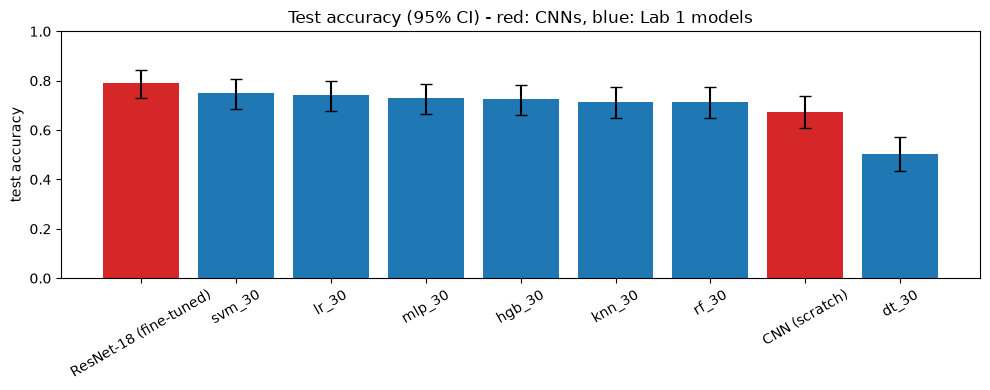

In [29]:
CNN, RESNET = "CNN (scratch)", "ResNet-18 (fine-tuned)"
test_proba = {CNN: cnn_proba, RESNET: ft_proba, **{name: p for name, (p, _) in lab1.items()}}
test_pred = {name: p.argmax(axis=1) for name, p in test_proba.items()}

rows = []
for name, pred in test_pred.items():
    acc, lo, hi = UF.accuracy_ci(y_test, pred)
    rows.append({"model": name, "test acc": acc, "CI low": lo, "CI high": hi})
results_df = pd.DataFrame(rows).sort_values("test acc", ascending=False).reset_index(drop=True)
display(results_df.round(3))
results_df.to_csv("lab2_test_results.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(results_df["model"], results_df["test acc"],
       yerr=[results_df["test acc"] - results_df["CI low"], results_df["CI high"] - results_df["test acc"]], capsize=4,
       color=["tab:red" if m in (CNN, RESNET) else "tab:blue" for m in results_df["model"]])
ax.set(ylabel="test accuracy", ylim=(0, 1), title="Test accuracy (95% CI) - red: CNNs, blue: Lab 1 models")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

<a id="7-rq"></a>
## 7. Research questions

<a id="rq1"></a>
### RQ1. Do learned features beat hand-crafted descriptors?
All models are compared on the same test songs (table above). Because they are tested on the same songs, we use a paired test: the exact **McNemar test** compares the number of songs that only model A gets right with the number that only model B gets right.

In [30]:
rq1 = []
for a, b in [(CNN, BEST_LAB1), (RESNET, BEST_LAB1), (RESNET, CNN)]:
    only_a, only_b, p = UF.mcnemar(y_test, test_pred[a], test_pred[b])
    rq1.append({"model A": a, "model B": b, "acc A": np.mean(test_pred[a] == y_test),
                "acc B": np.mean(test_pred[b] == y_test), "only A right": only_a, "only B right": only_b,
                "McNemar p": p})
rq1_df = pd.DataFrame(rq1)
display(rq1_df.round(3))

,model A,model B,acc A,acc B,only A right,only B right,McNemar p
0,CNN (scratch),svm_30,0.675,0.751,22,37,0.067
1,ResNet-18 (fine-tuned),svm_30,0.792,0.751,26,18,0.291
2,ResNet-18 (fine-tuned),CNN (scratch),0.792,0.675,35,12,0.001


On this test split, the scratch CNN (67.5%) did not significantly differ from the best Lab 1 model, `svm_30` (75.1%; McNemar p = 0.067). Fine-tuned ResNet-18 achieved 79.2%, but its difference from `svm_30` was also not significant (p = 0.291). ResNet-18 did significantly outperform the scratch CNN (p = 0.001). Thus, learned features from a pretrained network performed best numerically, but these results do not show a statistically significant advantage over the hand-crafted descriptor SVM; the scratch CNN did not beat it.

<a id="rq2"></a>
### RQ2. Do CNNs and descriptor models make the same mistakes?
* Confusion matrices of the CNN, the ResNet and the best Lab 1 model.
* Error overlap: number of test songs both models get wrong, compared with the number expected if the errors were independent (errors A × errors B / n), and how often they predict the same wrong genre.
* Genre-similarity structure: for each model we count how often each pair of genres is confused (in both directions) and compute the Spearman correlation of these counts between models. A high correlation means the models find the same genres similar, i.e. the similarity structure of Lab 1 is a property of the music and not only of the descriptors.

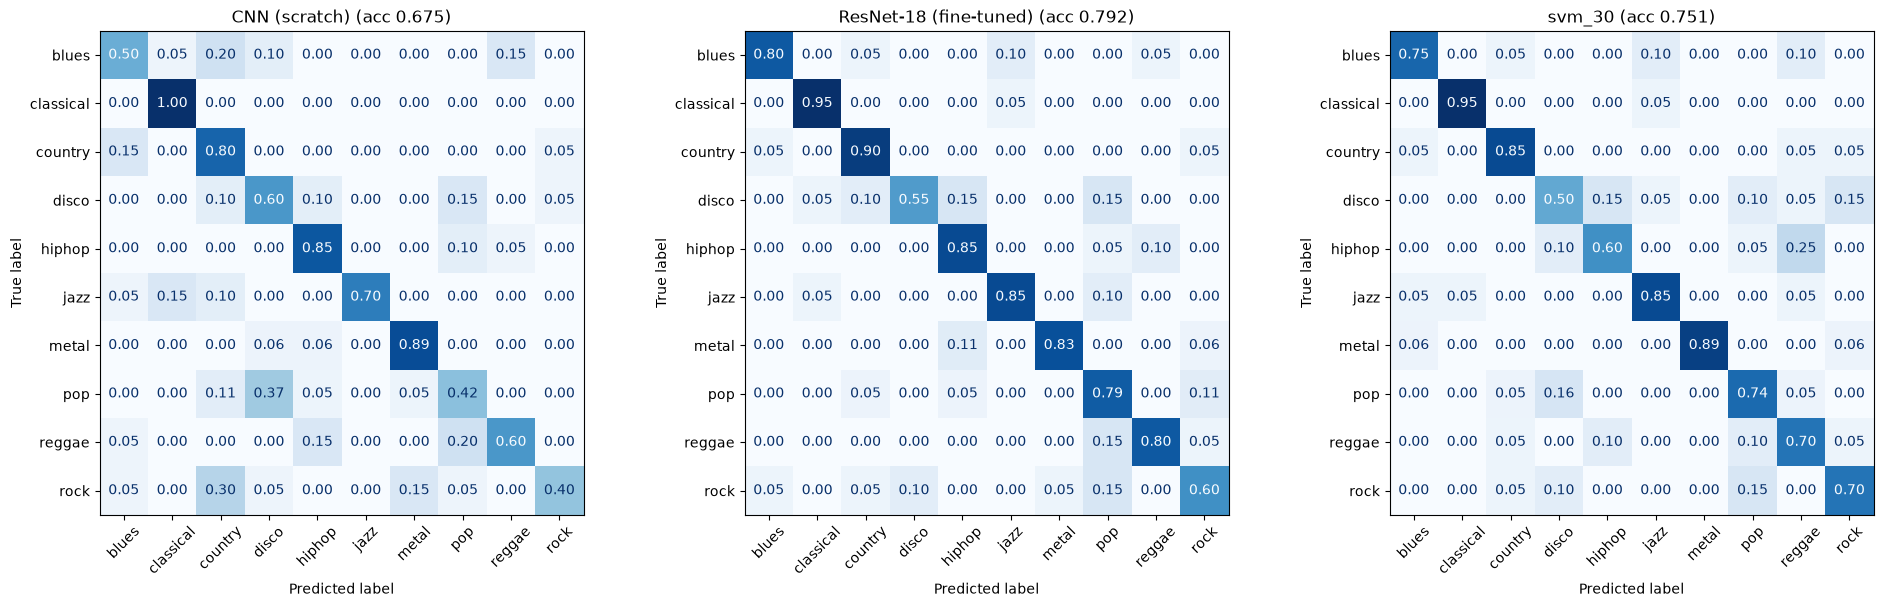

In [31]:
rq2_models = [CNN, RESNET, BEST_LAB1]
UF.plot_confusion_matrices({m: test_pred[m] for m in rq2_models}, y_test, classes)

In [32]:
from sklearn.metrics import confusion_matrix
from scipy.stats import spearmanr

n = len(y_test)
overlap = []
for a, b in [(CNN, BEST_LAB1), (RESNET, BEST_LAB1), (CNN, RESNET)]:
    wrong_a, wrong_b = test_pred[a] != y_test, test_pred[b] != y_test
    both = wrong_a & wrong_b
    overlap.append({"model A": a, "model B": b, "errors A": wrong_a.sum(), "errors B": wrong_b.sum(),
                    "both wrong": both.sum(), "expected if independent": wrong_a.sum() * wrong_b.sum() / n,
                    "only A wrong": (wrong_a & ~wrong_b).sum(), "only B wrong": (~wrong_a & wrong_b).sum(),
                    "same wrong genre (of both wrong)": np.mean(test_pred[a][both] == test_pred[b][both])})
display(pd.DataFrame(overlap).round(3))

# genre pairs that are confused (both directions added up)
def confused_pairs(pred):
    cm = confusion_matrix(y_test, pred, labels=range(len(classes)))
    sym = cm + cm.T
    i, j = np.triu_indices(len(classes), k=1)
    return pd.Series(sym[i, j], index=[f"{classes[a]}-{classes[b]}" for a, b in zip(i, j)])

pairs = pd.DataFrame({m: confused_pairs(test_pred[m]) for m in rq2_models})
print("Most confused genre pairs (number of test songs):")
display(pairs.sort_values(BEST_LAB1, ascending=False).head(10))

corr = pairs.corr(method="spearman")
print("Spearman correlation of the genre-confusion counts:")
display(corr.round(2))

,model A,model B,errors A,errors B,both wrong,expected if independent,only A wrong,only B wrong,same wrong genre (of both wrong)
0,CNN (scratch),svm_30,64,49,27,15.919,37,22,0.481
1,ResNet-18 (fine-tuned),svm_30,41,49,23,10.198,18,26,0.652
2,CNN (scratch),ResNet-18 (fine-tuned),64,41,29,13.320,35,12,0.483


Most confused genre pairs (number of test songs):


,CNN (scratch),ResNet-18 (fine-tuned),svm_30
hiphop-reggae,4,2,7
disco-rock,2,2,5
disco-hiphop,2,3,5
disco-pop,10,3,5
pop-rock,1,5,3
pop-reggae,4,3,3
blues-jazz,1,2,3
country-reggae,0,0,2
country-rock,7,2,2
classical-jazz,3,2,2


Spearman correlation of the genre-confusion counts:


,CNN (scratch),ResNet-18 (fine-tuned),svm_30
CNN (scratch),1.00,0.73,0.59
ResNet-18 (fine-tuned),0.73,1.00,0.68
svm_30,0.59,0.68,1.00


The models shared more errors than expected if their errors were independent: for example, the CNN and `svm_30` both got 27 songs wrong (15.9 expected), and ResNet-18 and `svm_30` both got 23 wrong (10.2 expected). Among songs both models got wrong, ResNet-18 and `svm_30` predicted the same wrong genre 65.2% of the time; the corresponding proportions were about 48% for the other pairs. Genre-confusion patterns were positively, moderately correlated (Spearman ρ = 0.59 for CNN–SVM, 0.68 for ResNet–SVM, and 0.73 for CNN–ResNet). This suggests some shared difficult songs and genre confusions, alongside model-specific errors.

<a id="rq3"></a>
### RQ3. Are the two approaches complementary?
1. **Ensemble (late fusion):** average of the class probabilities of a CNN and the best Lab 1 model.
2. **Feature concatenation (early fusion):** the hidden layer of the final CNN concatenated with the 57 F30 descriptors, classified with logistic regression. Compared with descriptors only and embeddings only.

In [33]:
fusion = []
for a in [CNN, RESNET]:
    avg = (test_proba[a] + test_proba[BEST_LAB1]) / 2
    fusion.append({"ensemble": f"{a} + {BEST_LAB1}", "acc A": np.mean(test_pred[a] == y_test),
                   "acc B": np.mean(test_pred[BEST_LAB1] == y_test),
                   "averaged probabilities acc": np.mean(avg.argmax(1) == y_test),
                   "at least one right (upper bound)": np.mean((test_pred[a] == y_test) | (test_pred[BEST_LAB1] == y_test))})
display(pd.DataFrame(fusion).round(3))

,ensemble,acc A,acc B,averaged probabilities acc,at least one right (upper bound)
0,CNN (scratch) + svm_30,0.675,0.751,0.802,0.863
1,ResNet-18 (fine-tuned) + svm_30,0.792,0.751,0.832,0.883


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

f30 = pd.read_csv(DATA_DIR / "features_30_sec.csv").set_index("filename")
feature_cols = [c for c in f30.columns if c not in ("length", "label")]
var_cols = [c for c in feature_cols if c.endswith("_var")]
f30[var_cols] = np.log1p(f30[var_cols])           # same log transform of the *_var columns as in Lab 1

train_files = data["filenames"][split["trainval"]]
y_train = labels[split["trainval"]]
desc_train, desc_test = f30.loc[train_files, feature_cols].to_numpy(), f30.loc[test_files, feature_cols].to_numpy()
emb_train = UF.get_embeddings(cnn_model, data, CNN_CONFIG, split["trainval"], device)
emb_test = UF.get_embeddings(cnn_model, data, CNN_CONFIG, split["test"], device)

feature_sets = {
    "descriptors only": (desc_train, desc_test),
    "CNN embedding only": (emb_train, emb_test),
    "CNN embedding + descriptors": (np.hstack([emb_train, desc_train]), np.hstack([emb_test, desc_test])),
}
rq3 = []
for name, (X_tr, X_te) in feature_sets.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=5000))
    clf.fit(X_tr, y_train)
    rq3.append({"features": name, "n features": X_tr.shape[1], "test acc": clf.score(X_te, y_test)})
display(pd.DataFrame(rq3).round(3))

,features,n features,test acc
0,descriptors only,57,0.736
1,CNN embedding only,64,0.701
2,CNN embedding + descriptors,121,0.817


Both forms of fusion improved on their constituent single models on this test split. Averaging probabilities reached 80.2% for CNN + `svm_30` and 83.2% for ResNet-18 + `svm_30`, versus 67.5%, 79.2%, and 75.1% for the individual models. Concatenating CNN embeddings with descriptors and fitting logistic regression reached 81.7%, compared with 73.6% for descriptors alone and 70.1% for embeddings alone. 

<a id="rq5"></a>
### RQ5. How much does one 80/20 split tell you?
With ≈197 test songs one song is 0.5 % of accuracy. We repeat the evaluation on 3 stratified 80/20 splits (seeds 42, 123, 8): the final CNN and ResNet configurations are retrained on the 80 % of each split, and the Lab 1 models are loaded from `lab1_predictions/<model>_seed<seed>.csv`. (The hyper-parameters were chosen on the seed-42 split and are kept fixed.)

In [35]:
rq5 = []
for seed in RQ5_SEEDS:
    sp = splits[seed]
    y_te = labels[sp["test"]]
    if seed == SEED:
        accs = {CNN: np.mean(cnn_pred == y_test), RESNET: np.mean(ft_pred == y_test)}
    else:
        accs = {}
        for name, config in [(CNN, CNN_CONFIG), (RESNET, FT_CONFIG)]:
            model, _ = UF.train_model(config, data, sp["trainval"], None, device, seed=seed)
            accs[name] = np.mean(UF.predict(model, data, config, sp["test"], device)[1] == y_te)
            del model
    for name, (_, pred) in load_lab1(seed).items():
        accs[name] = np.mean(pred == y_te)
    for name, acc in accs.items():
        rq5.append({"seed": seed, "model": name, "test acc": acc})
    print(seed, {k: round(v, 3) for k, v in accs.items()})

rq5_df = pd.DataFrame(rq5).pivot(index="model", columns="seed", values="test acc")
rq5_df["mean"], rq5_df["std"] = rq5_df[RQ5_SEEDS].mean(axis=1), rq5_df[RQ5_SEEDS].std(axis=1)
rq5_df["min"], rq5_df["max"] = rq5_df[RQ5_SEEDS].min(axis=1), rq5_df[RQ5_SEEDS].max(axis=1)
rq5_df = rq5_df.sort_values("mean", ascending=False)
display(rq5_df.round(3))
print("Best model on each split:", rq5_df[RQ5_SEEDS].idxmax().to_dict())

fig, ax = plt.subplots(figsize=(10, 4))
for seed in RQ5_SEEDS:
    ax.plot(rq5_df.index, rq5_df[seed], "o", alpha=0.6, label=f"seed {seed}")
ax.errorbar(rq5_df.index, rq5_df["mean"], yerr=rq5_df["std"], fmt="s", color="black", capsize=5, label="mean ± std")
ax.set(ylabel="test accuracy", title="Test accuracy on 3 different 80/20 splits")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

if BEST_LAB1 in rq5_df.index:
    for m in [CNN, RESNET]:
        diff = rq5_df.loc[m, RQ5_SEEDS] - rq5_df.loc[BEST_LAB1, RQ5_SEEDS]
        print(f"{m} - {BEST_LAB1}: mean difference {diff.mean():+.3f} (std {diff.std():.3f}), "
              f"{m} better on {(diff > 0).sum()} of {len(diff)} splits")

42 {'CNN (scratch)': np.float64(0.675), 'ResNet-18 (fine-tuned)': np.float64(0.792), 'dt_30': np.float64(0.503), 'hgb_30': np.float64(0.726), 'knn_30': np.float64(0.716), 'lr_30': np.float64(0.741), 'mlp_30': np.float64(0.731), 'rf_30': np.float64(0.716), 'svm_30': np.float64(0.751)}
123 {'CNN (scratch)': np.float64(0.594), 'ResNet-18 (fine-tuned)': np.float64(0.792), 'dt_30': np.float64(0.497), 'hgb_30': np.float64(0.69), 'knn_30': np.float64(0.66), 'lr_30': np.float64(0.68), 'mlp_30': np.float64(0.726), 'rf_30': np.float64(0.65), 'svm_30': np.float64(0.721)}
8 {'CNN (scratch)': np.float64(0.548), 'ResNet-18 (fine-tuned)': np.float64(0.777), 'dt_30': np.float64(0.482), 'hgb_30': np.float64(0.761), 'knn_30': np.float64(0.716), 'lr_30': np.float64(0.741), 'mlp_30': np.float64(0.756), 'rf_30': np.float64(0.665), 'svm_30': np.float64(0.736)}


seed,8,42,123,mean,std,min,max
model,,,,,,,
ResNet-18 (fine-tuned),0.777,0.792,0.792,0.787,0.009,0.777,0.792
mlp_30,0.756,0.731,0.726,0.738,0.016,0.726,0.756
svm_30,0.736,0.751,0.721,0.736,0.015,0.721,0.751
hgb_30,0.761,0.726,0.690,0.726,0.036,0.690,0.761
lr_30,0.741,0.741,0.680,0.721,0.035,0.680,0.741
knn_30,0.716,0.716,0.660,0.697,0.032,0.660,0.716
rf_30,0.665,0.716,0.650,0.677,0.035,0.650,0.716
CNN (scratch),0.548,0.675,0.594,0.606,0.064,0.548,0.675
dt_30,0.482,0.503,0.497,0.494,0.011,0.482,0.503


Best model on each split: {42: 'ResNet-18 (fine-tuned)', 123: 'ResNet-18 (fine-tuned)', 8: 'ResNet-18 (fine-tuned)'}


CNN (scratch) - svm_30: mean difference -0.130 (std 0.056), CNN (scratch) better on 0 of 3 splits
ResNet-18 (fine-tuned) - svm_30: mean difference +0.051 (std 0.018), ResNet-18 (fine-tuned) better on 3 of 3 splits


Across the three evaluated splits, the scratch CNN varied substantially (mean 60.6%, SD 6.4 percentage points, range 54.8–67.5%), while ResNet-18 was more consistent (mean 78.7%, SD 0.9 points, range 77.7–79.2%). The best Lab 1 SVM averaged 73.6% (SD 1.5 points, range 72.1–75.1%). ResNet-18 ranked first on all three splits; `svm_30` also outperformed the scratch CNN on all three. The CNN's split-to-split variability was large relative to the average 13-point gap between it and the SVM. 

This is suggestive, but only three splits were evaluated, so it is not a robust estimate over all possible splits.